# AD49F Group 8 — Sector Momentum and the Cash Filter

**Research question:** Do momentum-based sector selection and a cash filter improve risk-adjusted performance after trading costs?

We use nine U.S. sector ETFs and rank them by their past six-month returns. We make decisions at month-end and rebalance at the next trading day's close.

| Portfolio | Rule |
|---|---|
| P1 | Allocate 1/9 to each of the nine sector ETFs. |
| P2 | Allocate 50% to each of the two highest-ranked ETFs. |
| P3 | Same as P1, but keep an ETF's share in cash if its six-month return is zero or negative. |
| P4 | Same as P2, but keep a selected ETF's share in cash if its six-month return is zero or negative. |
| Benchmark | Buy and hold SPY. |

**How to run:** Run Parts 1–3 in order. Parts 1 and 2 report annualized return, maximum drawdown, and Sharpe ratio with and without trading costs. Part 3 adds a random two-sector benchmark for P2 in the final test period.

## Part 1 — Development Backtest (2001–2015)

We check the backtest implementation and examine how the predefined strategies performed in the earlier period.

Veri: 2000-06-01 – 2015-12-31, 3921 işlem günü
Eksik veri yok.

Kontroller (2001–2015):
  ✓ Sıfır maliyet: günlük seri eski sonuçlarla aynı (en büyük fark 1.9e-12 $)
  ✓ Maliyetli: dönem sonu (işlem öncesi) değerleri aynı (en büyük fark 0.0e+00 $)
  ✓ Maliyetli: son gün değeri aynı (en büyük fark 0.0e+00 $)
  ✓ Maliyetli: yeniden dengeleme dışındaki günler aynı (en büyük fark 0.0e+00 $)
  ✓ Maliyetli: dengeleme günü farkı = o günün maliyeti (en büyük fark 8.9e-13 $)

Aylık karar tablosu (180 satır, ekranda ilk ve son 3):
     Karar      İşlem Dönem sonu              İlk iki  Pozitif ETF  P3 nakit %  P4 nakit %  P1 ($)  P1 maliyetli ($)  P2 ($)  P2 maliyetli ($)  P3 ($)  P3 maliyetli ($)  P4 ($)  P4 maliyetli ($)
2000-12-29 2001-01-02 2001-02-01 XLF 25.0%, XLU 24.6%            7        22.2         0.0  104.97            104.86   99.88             99.78  100.56            100.48   99.88             99.78
2001-01-31 2001-02-01 2001-03-01 XLU 15.8%, XLF 14.6%            8        11.1     

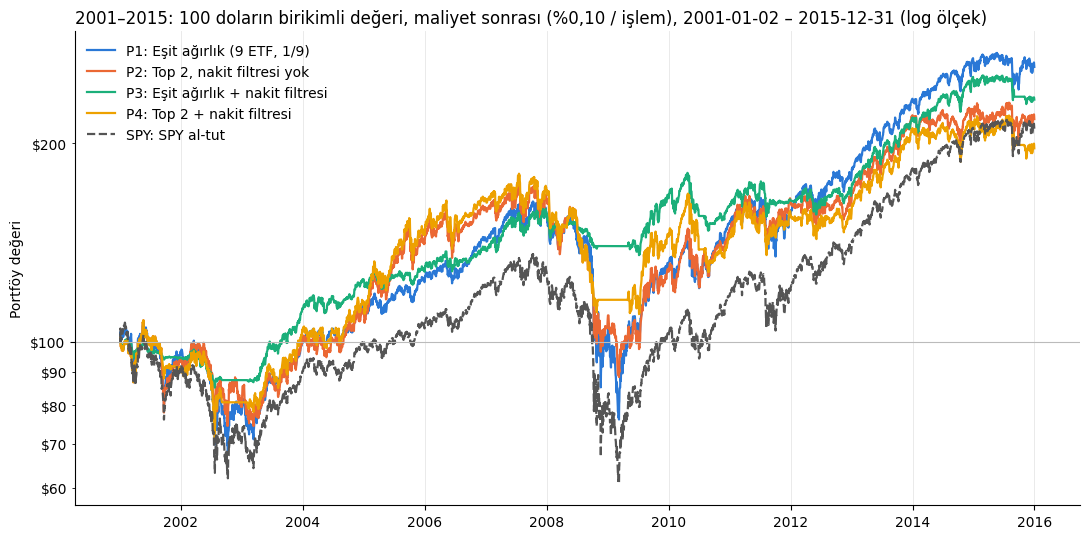

In [4]:
!pip install -q yfinance

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)

# ================= AYARLAR (değişmedi) =================
ETFLER = ["XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]
KIYAS = "SPY"
SEMBOLLER = ETFLER + [KIYAS]
SERMAYE = 100.0
GERI_BAKIS = 6       # ay

# Maliyet senaryosu (VARSAYIM): işlem yapılan tutar üzerinden, alışta ve satışta ayrı ayrı
KOMISYON = 0.0005    # %0,05
SLIPPAGE = 0.0005    # %0,05
RISKSIZ_GETIRI = 0.0 # Sharpe için yıllık risksiz getiri (nakit faizi de sıfır)
YIL_GUN = 252

PORTFOYLER = {
    "P1": "Eşit ağırlık (9 ETF, 1/9)",
    "P2": "Top 2, nakit filtresi yok",
    "P3": "Eşit ağırlık + nakit filtresi",
    "P4": "Top 2 + nakit filtresi",
}
ETIKETLER = {**PORTFOYLER, "SPY": "SPY al-tut"}
renkler = {"P1": "#2a78d6", "P2": "#eb6834", "P3": "#1baf7a", "P4": "#eda100", "SPY": "#555555"}
dolar = FuncFormatter(lambda v, _: f"${v:,.0f}")
yuzde = lambda x: f"%{x*100:.2f}".replace(".", ",")


# ================= STRATEJİ (değişmedi) =================
def hedef_agirliklar(getiri):
    """Her portföy için {ETF: ağırlık}; 1'e tamamlanmayan kısım nakittir."""
    ilk_iki = list(getiri.index[:2])
    return {
        "P1": {e: 1/9 for e in ETFLER},
        "P2": {e: 0.50 for e in ilk_iki},
        "P3": {e: 1/9 for e in ETFLER if getiri[e] > 0},      # Kalan pay nakitte, dağıtılmaz
        "P4": {e: 0.50 for e in ilk_iki if getiri[e] > 0},
    }


# ================= VERİ VE SİNYALLER =================
def veri_hazirla(indir_bas, indir_son_haric, ilk_karar_ayi, son_karar_ayi, son_yil):
    """Veriyi indirir, eksikleri raporlar, karar/işlem tarihlerini ve sinyalleri kurar."""
    global fiyat, gunler, son_gun, ilk_islem, sinyaller
    veri = yf.download(SEMBOLLER, start=indir_bas, end=indir_son_haric,
                       auto_adjust=False, progress=False)
    if veri.empty:
        raise SystemExit("UYARI: Veri boş geldi. İnternet bağlantısını veya sembolleri kontrol edin.")

    fiyat = veri["Adj Close"].reindex(columns=SEMBOLLER)   # Satır silinmiyor (dropna yok)
    gunler = fiyat.index

    eksik = fiyat.isna().stack().loc[lambda s: s].reset_index()
    eksik.columns = ["Tarih", "Sembol", "Eksik"]
    eksik = eksik[["Sembol", "Tarih"]]
    print(f"Veri: {gunler[0].date()} – {gunler[-1].date()}, {len(gunler)} işlem günü")
    if eksik.empty:
        print("Eksik veri yok.\n")
    else:
        print(f"UYARI: {len(eksik)} eksik fiyat var (tarihler silinmedi):")
        print(eksik.groupby("Sembol")["Tarih"].agg(["count", "min", "max"])
              .rename(columns={"count": "Eksik gün", "min": "İlk", "max": "Son"}))
        print(eksik.head(20).to_string(index=False))
        print("Hesapta eksik bir fiyata denk gelinirse kod durur.\n")

    ay_sonu = pd.Series(gunler, index=gunler).groupby(gunler.to_period("M")).last()
    son_gun = gunler[gunler.year == son_yil][-1]

    tarihler = []
    for ay in pd.period_range(ilk_karar_ayi, son_karar_ayi, freq="M"):
        karar = ay_sonu[ay]
        tarihler.append((karar, ay_sonu[ay - GERI_BAKIS], gunler[gunler > karar][0]))
    ilk_islem = tarihler[0][2]

    sinyaller = []   # (karar, işlem, dönem sonu, getiri, hedef ağırlıklar)
    for k, (karar, geri, islem) in enumerate(tarihler):
        bitis = tarihler[k + 1][2] if k + 1 < len(tarihler) else son_gun
        # Sadece karar tarihi ve 6 ay önceki ay sonu fiyatları kullanılır
        getiri = (fiyat_al(karar, ETFLER) / fiyat_al(geri, ETFLER) - 1).sort_values(ascending=False)
        sinyaller.append((karar, islem, bitis, getiri, hedef_agirliklar(getiri)))
    return eksik, tarihler


def fiyat_al(tarih, semboller):
    """Fiyatları döndürür; eksik varsa sessizce geçmez, hata verir."""
    p = fiyat.loc[tarih, semboller]
    if p.isna().any():
        raise ValueError(f"{tarih.date()} tarihinde eksik fiyat: {list(p[p.isna()].index)}")
    return p


# ================= BACKTEST =================
def deger_serisi(pozisyon, nakit, islem, bitis):
    """İşlem günü kapanışındaki $ pozisyonlarını bitiş gününe kadar tutar.
    Günlük (toplam değer, ETF'lerdeki değer) döndürür."""
    aralik = fiyat.loc[islem:bitis]
    if not pozisyon:
        return pd.Series(nakit, index=aralik.index), pd.Series(0.0, index=aralik.index)
    semb = list(pozisyon)
    if aralik[semb].isna().any().any():
        eksik = aralik[semb].isna().stack()
        raise ValueError(f"Elde tutma döneminde eksik fiyat: {list(eksik[eksik].index[:5])}")
    etf = ((aralik[semb] / fiyat_al(islem, semb)) * pd.Series(pozisyon)).sum(axis=1)
    return nakit + etf, etf


def yeniden_dengele(pozisyon, nakit, hedef_w, maliyet_orani):
    """
    Mevcut $ pozisyonlarını hedef ağırlıklara getirir.
    Maliyet = oran x gerçekten alınıp satılan tutar (|hedef - mevcut| toplamı).
    Maliyet portföy değerini düşürdüğü için hedefler de küçülür; birkaç turda dengeye gelir.
    """
    deger = nakit + sum(pozisyon.values())
    sonrasi = deger
    for _ in range(100):
        hedef = {e: sonrasi * w for e, w in hedef_w.items()}
        hacim = sum(abs(hedef.get(e, 0.0) - pozisyon.get(e, 0.0)) for e in set(hedef) | set(pozisyon))
        yeni = deger - maliyet_orani * hacim
        if abs(yeni - sonrasi) < 1e-12:
            break
        sonrasi = yeni
    hedef = {e: sonrasi * w for e, w in hedef_w.items()}
    yeni_nakit = sonrasi - sum(hedef.values())
    return hedef, yeni_nakit, hacim


def backtest(komisyon, slippage):
    """
    Günlük seri kuralı (DÜZELTİLMİŞ):
      - Yeniden dengeleme gününe kadarki getiri eski pozisyonlardan gelir (kapanış fiyatıyla).
      - O günün değeri, kapanıştaki işlemler ve maliyetler SONRASI portföy değeridir.
    """
    oran = komisyon + slippage
    durum = {p: ({}, SERMAYE) for p in PORTFOYLER}       # ( {ETF: $}, nakit $ )
    yeni_parca = {p: [] for p in PORTFOYLER}             # Düzeltilmiş günlük seri
    eski_parca = {p: [] for p in PORTFOYLER}             # Önceki sürümün serisi (sadece kontrol)
    pay_parca = {p: [] for p in PORTFOYLER}              # Günlük gerçek ETF payı
    hacimler = {p: 0.0 for p in PORTFOYLER}
    maliyetler = {p: {} for p in PORTFOYLER}             # {işlem tarihi: ödenen maliyet $}
    ay_sonu_degerleri = []
    son_k = len(sinyaller) - 1

    for k, (karar, islem, bitis, getiri, hedef) in enumerate(sinyaller):
        satir = {}
        for p in PORTFOYLER:
            pozisyon, nakit = durum[p]
            pozisyon, nakit, hacim = yeniden_dengele(pozisyon, nakit, hedef[p], oran)
            hacimler[p] += hacim
            maliyetler[p][islem] = oran * hacim
            toplam, etf = deger_serisi(pozisyon, nakit, islem, bitis)
            pay = etf / toplam

            # Bitiş günü, bir sonraki dönemin ilk günü (işlem sonrası değer) olarak yazılır
            yeni_parca[p].append(toplam if k == son_k else toplam.iloc[:-1])
            pay_parca[p].append(pay if k == son_k else pay.iloc[:-1])
            # Önceki sürüm: bitiş günü işlem ÖNCESİ değerle kalıyordu
            eski_parca[p].append(toplam if k == 0 else toplam.iloc[1:])

            p_islem, p_bitis = fiyat_al(islem, list(pozisyon)), fiyat_al(bitis, list(pozisyon))
            durum[p] = ({e: v * p_bitis[e] / p_islem[e] for e, v in pozisyon.items()}, nakit)
            satir[p] = toplam.iloc[-1]                   # Dönem sonu, işlem öncesi
        ay_sonu_degerleri.append(satir)

    gunluk = pd.DataFrame({p: pd.concat(s) for p, s in yeni_parca.items()})
    eski = pd.DataFrame({p: pd.concat(s) for p, s in eski_parca.items()})
    etf_payi = pd.DataFrame({p: pd.concat(s) for p, s in pay_parca.items()})
    assert gunluk.index.is_unique and gunluk.index.equals(eski.index)

    # SPY al-tut: aynı kural, sadece başlangıçtaki alış maliyeti
    spy_poz, spy_nakit, spy_hacim = yeniden_dengele({}, SERMAYE, {KIYAS: 1.0}, oran)
    spy_toplam, spy_etf = deger_serisi(spy_poz, spy_nakit, ilk_islem, son_gun)
    gunluk["SPY"], eski["SPY"], etf_payi["SPY"] = spy_toplam, spy_toplam, spy_etf / spy_toplam
    hacimler["SPY"] = spy_hacim
    maliyetler["SPY"] = {ilk_islem: oran * spy_hacim}

    return {
        "gunluk": gunluk,
        "eski_gunluk": eski,
        "etf_payi": etf_payi,
        "ay_sonu": pd.DataFrame(ay_sonu_degerleri),
        "hacim": pd.Series(hacimler),
        "maliyet": pd.DataFrame(maliyetler).fillna(0.0),
    }


def eski_yontem():
    """Önceki sürümün maliyetsiz hesabı (ağırlık formülü) – sadece kontrol için."""
    degerler = {p: SERMAYE for p in PORTFOYLER}
    gunluk = {p: [] for p in PORTFOYLER}
    for k, (karar, islem, bitis, getiri, hedef) in enumerate(sinyaller):
        for p in PORTFOYLER:
            w = hedef[p]
            aralik = fiyat.loc[islem:bitis]
            if w:
                oran = aralik[list(w)] / fiyat.loc[islem, list(w)]
                seri = degerler[p] * ((1 - sum(w.values())) + (oran * pd.Series(w)).sum(axis=1))
            else:
                seri = pd.Series(degerler[p], index=aralik.index)
            gunluk[p].append(seri if k == 0 else seri.iloc[1:])
            degerler[p] = seri.iloc[-1]
    sonuc = pd.DataFrame({p: pd.concat(s) for p, s in gunluk.items()})
    spy = fiyat.loc[ilk_islem:son_gun, KIYAS]
    sonuc["SPY"] = SERMAYE * spy / spy.iloc[0]
    return sonuc


def kontrol_et(s0, sm, tol=1e-8):
    """Düzeltmenin sadece istenen yeri değiştirdiğini doğrular; sorun varsa durur."""
    islem_gunleri = [s[1] for s in sinyaller[1:]]        # İlk gün hariç yeniden dengeleme günleri
    bitisler = [s[2] for s in sinyaller]

    # 1) Sıfır maliyet: düzeltilmiş seri = eski sonuçlar (her gün)
    f1 = (s0["gunluk"] - eski_yontem()).abs().max().max()
    # 2) Maliyetli: dönem sonu (işlem öncesi) değerleri ve son değer değişmedi
    f2 = np.abs(sm["eski_gunluk"].loc[bitisler, list(PORTFOYLER)].values
                - sm["ay_sonu"][list(PORTFOYLER)].values).max()
    f3 = (sm["gunluk"].iloc[-1] - sm["eski_gunluk"].iloc[-1]).abs().max()
    # 3) Maliyetli: sadece yeniden dengeleme günleri değişti, fark tam o günün maliyeti
    fark = sm["eski_gunluk"] - sm["gunluk"]
    f4 = fark.drop(index=islem_gunleri).abs().max().max()
    f5 = (fark.loc[islem_gunleri, list(PORTFOYLER)]
          - sm["maliyet"].loc[islem_gunleri, list(PORTFOYLER)]).abs().max().max()

    for ad, f in [("Sıfır maliyet: günlük seri eski sonuçlarla aynı", f1),
                  ("Maliyetli: dönem sonu (işlem öncesi) değerleri aynı", f2),
                  ("Maliyetli: son gün değeri aynı", f3),
                  ("Maliyetli: yeniden dengeleme dışındaki günler aynı", f4),
                  ("Maliyetli: dengeleme günü farkı = o günün maliyeti", f5)]:
        assert f < tol, f"KONTROL BAŞARISIZ – {ad}: en büyük fark {f}"
        print(f"  ✓ {ad} (en büyük fark {f:.1e} $)")
    print()


# ================= RAPOR =================
def metrikler(s):
    """Yıllık bileşik getiri, maksimum düşüş ve yıllıklandırılmış Sharpe (100 $ başlangıç dahil)."""
    yil = (s.index[-1] - s.index[0]).days / 365.25
    cagr = (s.iloc[-1] / SERMAYE) ** (1 / yil) - 1
    tepe = np.maximum(s.cummax(), SERMAYE)
    maks_dusus = (s / tepe - 1).min()
    r = s.pct_change()
    r.iloc[0] = s.iloc[0] / SERMAYE - 1                  # İlk gün: başlangıç maliyetinin etkisi
    fazla = r - RISKSIZ_GETIRI / YIL_GUN
    sharpe = fazla.mean() / fazla.std() * np.sqrt(YIL_GUN)
    return cagr * 100, maks_dusus * 100, sharpe


def karar_tablosu_yap(s0, sm):
    tablo = pd.DataFrame([{
        "Karar": karar.date(), "İşlem": islem.date(), "Dönem sonu": bitis.date(),
        "İlk iki": ", ".join(f"{e} {getiri[e]*100:.1f}%" for e in getiri.index[:2]),
        "Pozitif ETF": int((getiri > 0).sum()),
        "P3 nakit %": round((1 - sum(hedef["P3"].values())) * 100, 1),
        "P4 nakit %": round((1 - sum(hedef["P4"].values())) * 100, 1),
    } for karar, islem, bitis, getiri, hedef in sinyaller])
    for p in PORTFOYLER:   # Dönem sonu kapanışında, yeniden dengeleme ÖNCESİ değer
        tablo[f"{p} ($)"] = s0["ay_sonu"][p].round(2)
        tablo[f"{p} maliyetli ($)"] = sm["ay_sonu"][p].round(2)
    return tablo


def sonuc_tablosu_yap(s0, sm):
    satirlar = []
    for c in s0["gunluk"].columns:
        g0, d0, sh0 = metrikler(s0["gunluk"][c])
        gm, dm, shm = metrikler(sm["gunluk"][c])
        satirlar.append({
            "Kod": c, "Portföy": ETIKETLER[c],
            "Yıllık getiri % maliyet öncesi": g0, "Yıllık getiri % maliyet sonrası": gm,
            "Maks. düşüş % maliyet öncesi": d0, "Maks. düşüş % maliyet sonrası": dm,
            "Sharpe (rf=0) maliyet öncesi": sh0, "Sharpe (rf=0) maliyet sonrası": shm,
            "Ort. ETF payı %": sm["etf_payi"][c].mean() * 100,
        })
    return pd.DataFrame(satirlar).set_index("Kod").round(2)


def maliyet_dokumu_yap(s0, sm):
    return pd.DataFrame({
        "Son değer maliyet öncesi ($)": s0["gunluk"].iloc[-1],
        "Son değer maliyet sonrası ($)": sm["gunluk"].iloc[-1],
        "İşlem hacmi ($)": sm["hacim"],
        "Komisyon ($)": sm["hacim"] * KOMISYON,
        "Slippage ($)": sm["hacim"] * SLIPPAGE,
    }).round(2)


def raporla(baslik, karar_tablosu, sonuc, maliyet_dokumu, sm):
    print(f"Aylık karar tablosu ({len(karar_tablosu)} satır, ekranda ilk ve son 3):")
    print(karar_tablosu.head(3).to_string(index=False))
    print("...")
    print(karar_tablosu.tail(3).to_string(index=False))
    print("Not: Tablodaki $ değerleri dönem sonu kapanışında, yeniden dengeleme ÖNCESİ değerlerdir.")

    print(f"\n{baslik}  {ilk_islem.date()} kapanışı – {son_gun.date()} kapanışı, başlangıç 100 $")
    print(sonuc.to_string())
    print("Varsayımlar: risksiz getiri %0 ve nakit faizi %0 (Sharpe = günlük getiri ort. / std x √252).")
    print(f"Maliyet senaryosu (VARSAYIM): komisyon {yuzde(KOMISYON)} + slippage {yuzde(SLIPPAGE)}, "
          "alışta ve satışta, sadece işlem yapılan tutar üzerinden. SPY'a yalnızca başlangıç alış "
          "maliyeti uygulandı; dönem sonunda satış maliyeti yok.")
    print("Getiri, maks. düşüş ve Sharpe düzeltilmiş günlük seriden (dengeleme günü = işlem ve maliyet "
          "sonrası değer) hesaplandı. Ort. ETF payı: maliyet sonrası serideki günlük "
          "(ETF değeri / portföy değeri) ortalaması.")
    print("\nMaliyet dökümü:")
    print(maliyet_dokumu.to_string())

    fig, ax = plt.subplots(figsize=(11, 5.5))
    for c in sm["gunluk"].columns:
        ax.plot(sm["gunluk"].index, sm["gunluk"][c], color=renkler[c], linewidth=1.6,
                linestyle="--" if c == "SPY" else "-", label=f"{c}: {ETIKETLER[c]}")
    ax.set_yscale("log")   # Eşit dikey mesafe = eşit yüzde değişim
    ax.yaxis.set_major_formatter(dolar)
    ax.yaxis.set_minor_formatter(dolar)
    ax.axhline(SERMAYE, color="#bbbbbb", linewidth=0.8)
    ax.grid(True, which="major", color="#e6e6e6", linewidth=0.6)
    for kenar in ["top", "right"]:
        ax.spines[kenar].set_visible(False)
    ax.set_title(f"{baslik}: 100 doların birikimli değeri, maliyet sonrası "
                 f"({yuzde(KOMISYON + SLIPPAGE)} / işlem), {ilk_islem.date()} – {son_gun.date()} (log ölçek)",
                 loc="left")
    ax.set_ylabel("Portföy değeri")
    ax.legend(frameon=False, loc="upper left")
    plt.tight_layout()
    plt.show()


# ================= 2001–2015 =================
eksik_tablo, _ = veri_hazirla("2000-06-01", "2016-01-01", "2000-12", "2015-11", 2015)

s0 = backtest(0.0, 0.0)               # Maliyet öncesi
sm = backtest(KOMISYON, SLIPPAGE)     # Maliyet sonrası
print("Kontroller (2001–2015):")
kontrol_et(s0, sm)

birikimli_0, birikimli_m = s0["gunluk"], sm["gunluk"]
etf_payi_0, etf_payi_m = s0["etf_payi"], sm["etf_payi"]   # Günlük gerçek ETF payı
karar_tablosu = karar_tablosu_yap(s0, sm)
sonuc = sonuc_tablosu_yap(s0, sm)
maliyet_dokumu = maliyet_dokumu_yap(s0, sm)
raporla("2001–2015", karar_tablosu, sonuc, maliyet_dokumu, sm)

## Part 2 — Final Backtest (2016–2025)

We apply the same rules to the later period and use the after-cost results for our main evaluation.

Kullanılan ayarlar (2001–2015 ile aynı):
  ETF'ler: ['XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY'], kıyas: SPY, başlangıç: 100.0 $, geriye bakış: 6 ay
  Komisyon: %0,05, slippage: %0,05 (VARSAYIM), risksiz getiri: %0,00, nakit faizi: %0

Veri: 2015-06-01 – 2025-12-31, 2664 işlem günü
Eksik veri yok.

Tarih kontrolü:
  İlk sinyal penceresi : 2015-06-30 kapanışı → 2015-12-31 kapanışı
  İlk işlem (başlangıç): 2016-01-04 kapanışı, tüm portföyler 100 $
  Son gün (bitiş)      : 2025-12-31 kapanışı
  Karar sayısı         : 120

Kontroller (2016–2025):
  ✓ Sıfır maliyet: günlük seri eski sonuçlarla aynı (en büyük fark 2.0e-12 $)
  ✓ Maliyetli: dönem sonu (işlem öncesi) değerleri aynı (en büyük fark 0.0e+00 $)
  ✓ Maliyetli: son gün değeri aynı (en büyük fark 0.0e+00 $)
  ✓ Maliyetli: yeniden dengeleme dışındaki günler aynı (en büyük fark 0.0e+00 $)
  ✓ Maliyetli: dengeleme günü farkı = o günün maliyeti (en büyük fark 9.8e-13 $)

Aylık karar tablosu (120 satır, ekranda ilk ve s

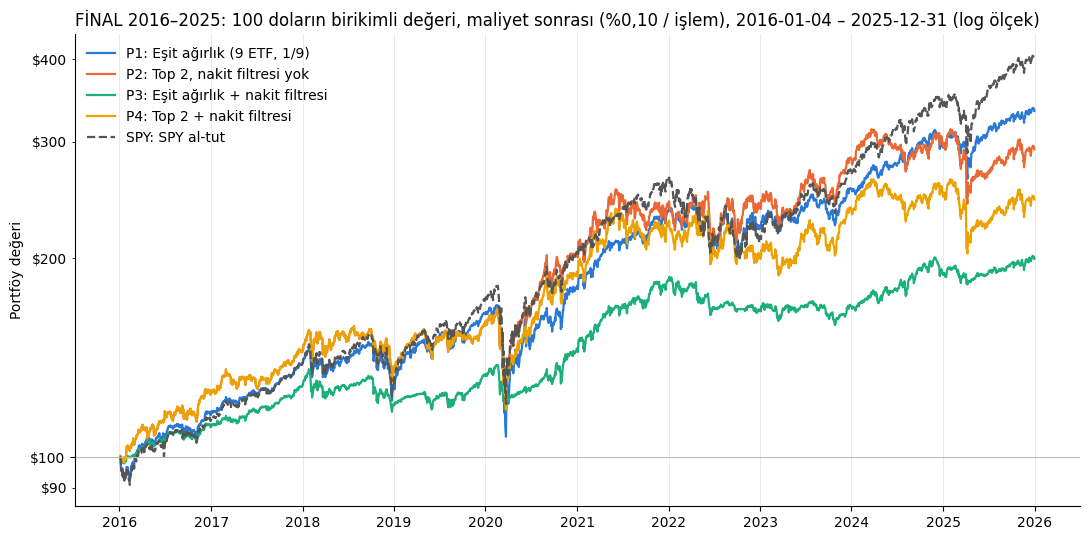

In [5]:
# ===================== FİNAL DÖNEMİ: 2016–2025 =====================
# 2001–2015 hücresinden SONRA çalıştırın. Aynı fonksiyonlar ve ayarlar kullanılır.
# 2001–2015 sonuçları (sonuc, birikimli_0, birikimli_m, etf_payi_0, etf_payi_m,
# karar_tablosu, maliyet_dokumu) değiştirilmez.

if "backtest" not in globals():
    raise SystemExit("Önce 2001–2015 hücresini çalıştırın.")

print("Kullanılan ayarlar (2001–2015 ile aynı):")
print(f"  ETF'ler: {ETFLER}, kıyas: {KIYAS}, başlangıç: {SERMAYE} $, geriye bakış: {GERI_BAKIS} ay")
print(f"  Komisyon: {yuzde(KOMISYON)}, slippage: {yuzde(SLIPPAGE)} (VARSAYIM), "
      f"risksiz getiri: {yuzde(RISKSIZ_GETIRI)}, nakit faizi: %0\n")

# Haziran 2015 – Aralık 2025 (ilk sinyal: Haziran–Aralık 2015 ay sonları)
final_eksik, f_tarihler = veri_hazirla("2015-06-01", "2026-01-01", "2015-12", "2025-11", 2025)

ilk_karar, ilk_geri = f_tarihler[0][0], f_tarihler[0][1]
print("Tarih kontrolü:")
print(f"  İlk sinyal penceresi : {ilk_geri.date()} kapanışı → {ilk_karar.date()} kapanışı")
print(f"  İlk işlem (başlangıç): {ilk_islem.date()} kapanışı, tüm portföyler 100 $")
print(f"  Son gün (bitiş)      : {son_gun.date()} kapanışı")
print(f"  Karar sayısı         : {len(sinyaller)}\n")
assert ilk_karar.year == 2015 and ilk_karar.month == 12, "İlk karar Aralık 2015 ay sonu olmalı"
assert ilk_islem == gunler[gunler.year == 2016][0], "İlk işlem 2016'nın ilk işlem günü olmalı"
assert son_gun.year == 2025 and son_gun.month == 12, "Veri Aralık 2025'e kadar gelmemiş"

final_s0 = backtest(0.0, 0.0)               # Maliyet öncesi
final_sm = backtest(KOMISYON, SLIPPAGE)     # Maliyet sonrası
print("Kontroller (2016–2025):")
kontrol_et(final_s0, final_sm)

final_b0, final_bm = final_s0["gunluk"], final_sm["gunluk"]
final_etf_payi_0, final_etf_payi_m = final_s0["etf_payi"], final_sm["etf_payi"]
final_karar_tablosu = karar_tablosu_yap(final_s0, final_sm)
final_sonuc = sonuc_tablosu_yap(final_s0, final_sm)
final_maliyet_dokumu = maliyet_dokumu_yap(final_s0, final_sm)
raporla("FİNAL 2016–2025", final_karar_tablosu, final_sonuc, final_maliyet_dokumu, final_sm)

## Manual Check — First P4 Decision

**Decision date:** 31 December 2015 · **Trade date:** 4 January 2016

We calculated the six-month returns of all nine sector ETFs in Excel using adjusted closing prices from 30 June and 31 December 2015.

| Rank | ETF | Six-month return | P4 target weight |
|---|---|---:|---:|
| 1 | XLP | 7.54% | 50% |
| 2 | XLU | 6.46% | 50% |

**Check result:** The Excel ranking matched the notebook. Both returns were positive, so the P4 rule allocated 50% to each ETF and left 0% in cash.

## Part 3 — Random Two-Sector Benchmark

As noted in the proposal, this optional test compares **P2** with repeated random two-sector selections under matching weights, timing and costs. The question is whether P2's six-month momentum ranking chooses better than picking two sectors at random.

**Design (2016–2025 final period):**

- **Trials:** 1,000 random portfolios with a fixed seed (42), so the results can be reproduced.
- **Selection:** Each month, every trial picks two *different* ETFs at random from the same nine sector ETFs (XLB, XLE, XLF, XLI, XLK, XLP, XLU, XLV, XLY).
- **Weights:** 50% / 50%, as in P2. No cash filter is applied.
- **Timing:** The same month-end decision dates and trade dates as Part 2. Trades happen at the close of the first trading day after each month-end. Each portfolio starts with \$100 at the close of the first trading day of January 2016 and ends at the close of the last trading day of 2025.
- **Costs (assumption):** 0.05% commission plus 0.05% slippage on the amount actually traded, on both buys and sells. On a rebalancing day, the daily value is the portfolio value after trades and costs.
- **Metric:** Annualized Sharpe ratio after costs, from daily values, with a risk-free rate and cash interest of 0%.

**Consistency check:** The cell first rebuilds P2 with the same engine used for the random trials. It confirms that the daily values and the after-cost Sharpe match Part 2 before running the trials.

**How to read the result:** The histogram shows the distribution of after-cost Sharpe ratios across the 1,000 random portfolios. The vertical line marks P2. The printed percentage is the share of random trials whose Sharpe is below P2's.

This comparison is descriptive and covers only one historical period. The portfolio weights, trading dates, and transaction-cost rules are the same for P2 and the random portfolios. The only difference is how the two sectors are selected.

Checks passed:
  P2 daily values reproduced from Part 2 (max diff 3.4e-13 $)
  P2 after-cost Sharpe used here: 0.6516  |  Part 2 table: 0.65

Random two-sector benchmark: 1000 trials, seed 42, 2016-01-04 close – 2025-12-31 close
  Monthly: two different ETFs drawn at random from the nine, 50/50, no cash filter
  Costs (assumption): commission 0.05% + slippage 0.05% on traded amount; risk-free rate and cash interest 0%
  Random Sharpe: median 0.62, 5th pct 0.38, 95th pct 0.85, min 0.15, max 1.11
  P2 Sharpe 0.65 beats 59.6% of the random trials


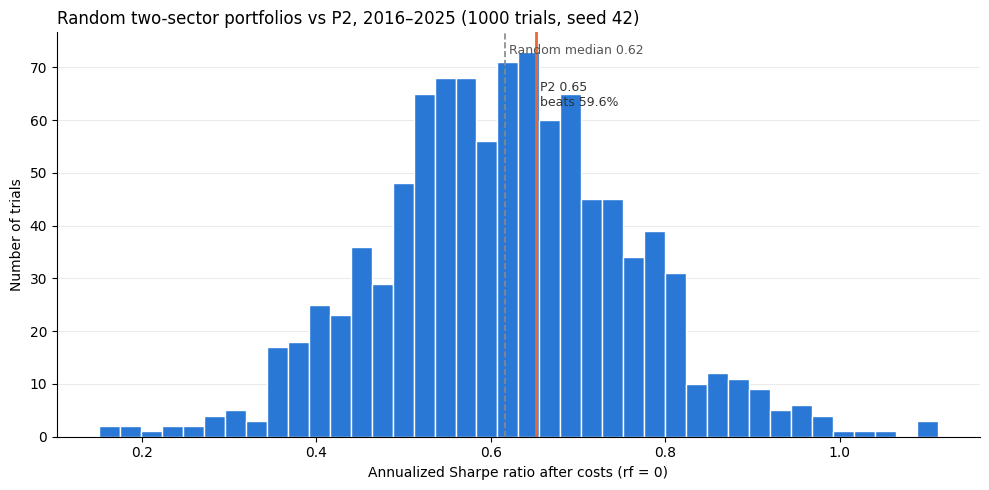

In [6]:
# ===================== PART 3 — RANDOM TWO-SECTOR BENCHMARK (2016–2025) =====================
# Run AFTER the 2001–2015 cell and the 2016–2025 cell. Read-only: nothing from Parts 1–2 is changed.

N_TRIALS = 1000
SEED = 42

# ---- 0) Make sure the notebook state is the 2016–2025 run ----
if "final_sm" not in globals():
    raise SystemExit("Run the 2001–2015 cell and then the 2016–2025 cell first.")
assert ilk_islem.year == 2016 and son_gun.year == 2025, (
    "Global data is not the 2016–2025 run. Re-run the 2016–2025 cell, then this cell.")

oran = KOMISYON + SLIPPAGE
tarih_index = fiyat.loc[ilk_islem:son_gun].index
P = fiyat.loc[ilk_islem:son_gun, ETFLER].to_numpy()
if np.isnan(P).any():
    raise SystemExit("Missing ETF prices in 2016–2025; the random benchmark needs all nine ETFs.")

pos_of = {d: i for i, d in enumerate(tarih_index)}
donemler = [(pos_of[islem], pos_of[bitis]) for _, islem, bitis, _, _ in sinyaller]   # same trade dates
etf_no = {e: i for i, e in enumerate(ETFLER)}


def iki_etf_backtest(secimler):
    """
    One portfolio, 50/50 in two ETFs each month, no cash filter.
    Same rules as Part 2: rebalance at the trade-day close, cost = (commission + slippage)
    x traded amount, daily value on a rebalance day = value AFTER trades and costs.
    secimler: list of (i, j) ETF column numbers, one pair per month.
    """
    pozisyon = np.zeros(len(ETFLER))      # $ in each ETF
    nakit = SERMAYE
    parcalar = []
    son_k = len(donemler) - 1
    for k, ((i0, i1), (a, b)) in enumerate(zip(donemler, secimler)):
        w = np.zeros(len(ETFLER)); w[a] = 0.5; w[b] = 0.5
        # Rebalance (same fixed-point cost rule as yeniden_dengele)
        deger = nakit + pozisyon.sum()
        sonrasi = deger
        for _ in range(100):
            hacim = np.abs(sonrasi * w - pozisyon).sum()
            yeni = deger - oran * hacim
            if abs(yeni - sonrasi) < 1e-12:
                break
            sonrasi = yeni
        pozisyon = sonrasi * w
        nakit = sonrasi - pozisyon.sum()
        # Hold until the next trade date
        oranlar = P[i0:i1 + 1] / P[i0]
        degerler = nakit + oranlar @ pozisyon
        parcalar.append(degerler if k == son_k else degerler[:-1])
        pozisyon = pozisyon * oranlar[-1]
    return pd.Series(np.concatenate(parcalar), index=tarih_index)


# ---- 1) Check: the same engine reproduces Part 2's P2 exactly ----
p2_secimler = [tuple(etf_no[e] for e in hedef["P2"]) for _, _, _, _, hedef in sinyaller]
p2_yeniden = iki_etf_backtest(p2_secimler)
fark = (p2_yeniden - final_sm["gunluk"]["P2"]).abs().max()
assert fark < 1e-8, f"Engine does not reproduce Part 2 P2 (max diff {fark})"

p2_sharpe = metrikler(p2_yeniden)[2]
p2_sharpe_part2 = metrikler(final_sm["gunluk"]["P2"])[2]
p2_sharpe_tablo = final_sonuc.loc["P2", "Sharpe (rf=0) maliyet sonrası"]
assert abs(p2_sharpe - p2_sharpe_part2) < 1e-10
assert abs(np.round(p2_sharpe, 2) - p2_sharpe_tablo) < 1e-9, "P2 Sharpe does not match the Part 2 table"
print("Checks passed:")
print(f"  P2 daily values reproduced from Part 2 (max diff {fark:.1e} $)")
print(f"  P2 after-cost Sharpe used here: {p2_sharpe:.4f}  |  Part 2 table: {p2_sharpe_tablo:.2f}\n")

# ---- 2) Random trials ----
rng = np.random.default_rng(SEED)
sharpe_listesi, son_deger_listesi = [], []
for _ in range(N_TRIALS):
    secimler = [tuple(rng.choice(len(ETFLER), size=2, replace=False)) for _ in donemler]
    seri = iki_etf_backtest(secimler)
    sharpe_listesi.append(metrikler(seri)[2])
    son_deger_listesi.append(seri.iloc[-1])

rastgele = pd.DataFrame({"Sharpe (after costs)": sharpe_listesi,
                         "Final value ($, after costs)": son_deger_listesi})
s = rastgele["Sharpe (after costs)"]
yuzde_gecti = (s < p2_sharpe).mean() * 100
esit = (s == p2_sharpe).sum()

print(f"Random two-sector benchmark: {N_TRIALS} trials, seed {SEED}, "
      f"{ilk_islem.date()} close – {son_gun.date()} close")
print(f"  Monthly: two different ETFs drawn at random from the nine, 50/50, no cash filter")
print(f"  Costs (assumption): commission {KOMISYON*100:.2f}% + slippage {SLIPPAGE*100:.2f}% "
      f"on traded amount; risk-free rate and cash interest 0%")
print(f"  Random Sharpe: median {s.median():.2f}, 5th pct {s.quantile(0.05):.2f}, "
      f"95th pct {s.quantile(0.95):.2f}, min {s.min():.2f}, max {s.max():.2f}")
print(f"  P2 Sharpe {p2_sharpe:.2f} beats {yuzde_gecti:.1f}% of the random trials"
      + (f" ({esit} ties)" if esit else ""))

# ---- 3) Histogram ----
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(s, bins=40, color="#2a78d6", edgecolor="white", linewidth=1)
ax.axvline(s.median(), color="#888888", linewidth=1.2, linestyle="--")
ax.axvline(p2_sharpe, color="#eb6834", linewidth=2)
ust = ax.get_ylim()[1]
ax.text(s.median(), ust * 0.97, f" Random median {s.median():.2f}", color="#555555",
        va="top", ha="left", fontsize=9)
sagda = p2_sharpe > s.quantile(0.9)          # Keep the P2 label inside the plot
ax.text(p2_sharpe, ust * 0.88,
        f"P2 {p2_sharpe:.2f} \nbeats {yuzde_gecti:.1f}% " if sagda else f" P2 {p2_sharpe:.2f}\n beats {yuzde_gecti:.1f}%",
        color="#333333", va="top", ha="right" if sagda else "left", fontsize=9)
ax.set_xlabel("Annualized Sharpe ratio after costs (rf = 0)")
ax.set_ylabel("Number of trials")
ax.set_title(f"Random two-sector portfolios vs P2, {ilk_islem.year}–{son_gun.year} "
             f"({N_TRIALS} trials, seed {SEED})", loc="left")
ax.grid(True, axis="y", color="#e6e6e6", linewidth=0.6)
ax.set_axisbelow(True)
for kenar in ["top", "right"]:
    ax.spines[kenar].set_visible(False)
plt.tight_layout()
plt.show()

**Result:** P2 achieved an after-cost Sharpe ratio of 0.65, compared with a median of 0.62 across 1,000 random two-sector portfolios. P2 beat 59.6% of the simulations, placing it modestly above the median in 2016–2025. This single-period comparison does not establish a persistent momentum advantage.